In [1]:
# !pip install pandas seaborn scipy scikit-learn matplotlib

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from sklearn.preprocessing import OneHotEncoder, LabelEncoder


In [2]:
df = sns.load_dataset('mpg')

rows, cols = df.shape # shape узнаёт размерность таблицы
print(f"Количество строк: {rows}")
print(f"Количество столбцов: {cols}")
print("\nПервые 5 строк датасета:")
df.head()


Количество строк: 398
Количество столбцов: 9

Первые 5 строк датасета:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### Описание признаков датасета автомобилей (mpg)

1. **mpg** (*Miles Per Gallon*) — миль на галлон. Главный показатель экономичности автомобиля. Чем выше это число, тем меньше машина «ест» бензина. Является **целевым столбцом**.
2. **cylinders** — цилиндры. Количество цилиндров в двигателе автомобиля (например: 4, 6 или 8).
3. **displacement** — объем двигателя. Суммарный объем всех цилиндров двигателя, измеряемый в кубических дюймах.
4. **horsepower** — лошадиные силы. Физическая мощность автомобильного двигателя.
5. **weight** — вес. Масса автомобиля, измеряемая в фунтах (lbs).
6. **acceleration** — ускорение. Время, за которое автомобиль разгоняется с 0 до 60 миль в час (в секундах).
7. **model_year** — год выпуска модели. Двузначное обозначение года (например, 70 означает 1970 год).
8. **origin** — происхождение. Регион или страна, где был произведен автомобиль (`usa` — США, `europe` — Европа, `japan` — Япония).
9. **name** — название. Полное текстовое наименование марки и конкретной модели автомобиля.


In [3]:
num_cols = df.select_dtypes(include=[np.number]).columns # Отбирает числовые данные, .columns забирает только название

num_eda = pd.DataFrame()
num_eda['Доля пропусков'] = df[num_cols].isna().mean()
num_eda['Минимум'] = df[num_cols].min()
num_eda['Максимум'] = df[num_cols].max()
num_eda['Среднее'] = df[num_cols].mean()
num_eda['Медиана'] = df[num_cols].median()
num_eda['Дисперсия'] = df[num_cols].var() # Разброс вокруг среднего значения
num_eda['Квантиль 0.1'] = df[num_cols].quantile(0.1) # Отсекает 10% самых маленьких значений.
num_eda['Квантиль 0.9'] = df[num_cols].quantile(0.9) # Отсекает 90% данных. Для acceleration это 19.0 секунд т.е. 90% машин разгоняются быстрее, чем за 19 секунд
num_eda['Квартиль 1'] = df[num_cols].quantile(0.25) # 25% значений датасета лежат ниже этой точки
num_eda['Квартиль 3'] = df[num_cols].quantile(0.75) # 75% всех значений лежат ниже этой точки

num_eda.T


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
Доля пропусков,0.000000,0.000000,0.000000,0.015075,0.000000,0.000000,0.000000
Минимум,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
Максимум,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000
Среднее,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
Медиана,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
Дисперсия,61.089611,2.893415,10872.199152,1481.569393,717140.990526,7.604848,13.672443
Квантиль 0.1,14.000000,4.000000,90.000000,67.000000,1988.500000,12.000000,71.000000
Квантиль 0.9,34.330000,8.000000,350.000000,157.700000,4275.200000,19.000000,81.000000
Квартиль 1,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
Квартиль 3,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000


In [4]:
# Отбирает категориальные (текстовые) признаки
cat_cols = df.select_dtypes(include=['object', 'category']).columns

cat_eda = pd.DataFrame() # Создаётся новая пустая таблица
cat_eda['Доля пропусков'] = df[cat_cols].isna().mean() 
cat_eda['Кол-во уникальных'] = df[cat_cols].nunique() 
cat_eda['Мода'] = df[cat_cols].mode().iloc[0] # .mode() находит эти значения, .iloc[0] берет самое первое из них
# Мода — это значение, которое встречается в столбце чаще всего (самое популярное значение)

cat_eda.T


C:\Users\Nickolay\AppData\Local\Temp\ipykernel_12348\2570506986.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


,origin,name
Доля пропусков,0.0,0.0
Кол-во уникальных,3,305
Мода,usa,ford pinto


In [ ]:
print("Проверка гипотезы 1 (отличается ли mpg у американских и европейских машин)")
df_clean = df.dropna(subset=['mpg']) # Удаляет пропуски для корректного теста
usa_mpg = df_clean[df_clean['origin'] == 'usa']['mpg'] # рахделяет данные нна независимык группы
europe_mpg = df_clean[df_clean['origin'] == 'europe']['mpg']


# t_stat — на сколько стандартных отклонений средние значения групп далеки друг от друга
# p_val1 — вероятность того, что h0 верна 
t_stat, p_val1 = stats.ttest_ind(usa_mpg, europe_mpg, equal_var=False) #stats.ttest_ind коэффициент Стьюдента
print(f"t-статистика: {t_stat:.4f}, p-value: {p_val1}")
if p_val1 < 0.05:
    print("Отклонить, mpg отличается.")
else:
    print("Не отклонить, значимых различий не обнаружено.")


# corr_val — само значение корреляции (меняется от -1 до 1)
# p_val2 — вероятность того, что эти две переменные на самом деле никак не связаны
print("\nПроверка Гипотезы 2 (связан ли weight с displacement)")
corr_val, p_val2 = stats.pearsonr(df_clean['weight'], df_clean['displacement']) 
print(f"Корреляция Пирсона: {corr_val:.4f}, p-value: {p_val2}")
if p_val2 < 0.05:
    print("Отклонить, между весом машины и объемом двигателя есть линейная связь.")
else:
    print("Не отклонить, связь не подтверждена.")


Проверка гипотезы 1 (отличается ли mpg у американских и европейских машин)
t-статистика: -8.6726, p-value: 5.1385856589422376e-14
Отклонить, mpg отличается.

Проверка Гипотезы 2 (связан ли weight с displacement)
Корреляция Пирсона: 0.9328, p-value: 1.2222258725034634e-177
Отклонить, между весом машины и объемом двигателя есть линейная связь.


Проверка


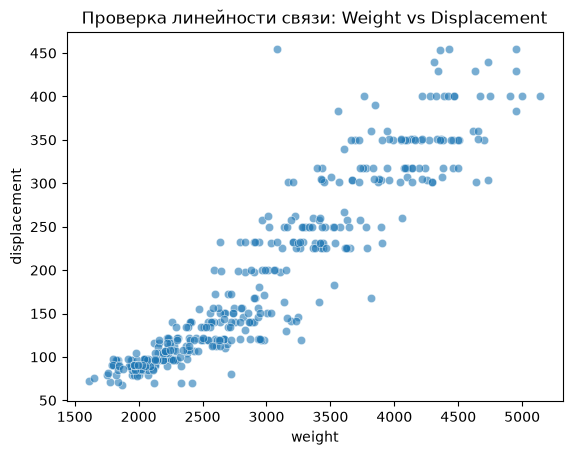

Шапиро p-value для mpg (USA): 0.00000
Шапиро p-value для mpg (Europe): 0.00840
Шапиро p-value для Weight: 0.00000

Гипотезы
Гипотеза 1 (отличается ли mpg у машин США и Европы):
t-статистика: -8.6726, p-value: 5.1385856589422376e-14
Вывод: Отклонить H0, mpg отличается.

Гипотеза 2 (связан ли weight с displacement):
Корреляция Пирсона: 0.9328, p-value: 1.2222258725034634e-177
Вывод: Отклонить H0, есть линейная связь.


In [ ]:
print("Проверка")

# Проверка ЛИНЕЙНОСТИ: строим один график рассеяния
# Если точки идут по диагонали без изгибов — связь линейная, Пирсон применим
sns.scatterplot(x=df_clean['weight'], y=df_clean['displacement'], alpha=0.6)
plt.title("Проверка линейности связи: Weight vs Displacement")
plt.show()

print(f"Шапиро mpg (USA): {stats.shapiro(usa_mpg)[1]:.5f}")
print(f"Шапиро mpg (Europe): {stats.shapiro(europe_mpg)[1]:.5f}")
print(f"Шапиро Weight: {stats.shapiro(df_clean['weight'])[1]:.5f}")


print("\nГипотезы")

print("Гипотеза 1 (отличается ли mpg у машин США и Европы):")
t_stat, p_val1 = stats.ttest_ind(usa_mpg, europe_mpg, equal_var=False) 
print(f"t-статистика: {t_stat:.4f}, p-value: {p_val1}")
print("Вывод: Отклонить H0, mpg отличается.\n" if p_val1 < 0.05 else "Вывод: Не отклонять H0.\n")

print("Гипотеза 2 (связан ли weight с displacement):")
corr_val, p_val2 = stats.pearsonr(df_clean['weight'], df_clean['displacement']) 
print(f"Корреляция Пирсона: {corr_val:.4f}, p-value: {p_val2}")
print("Вывод: Отклонить H0, есть линейная связь." if p_val2 < 0.05 else "Вывод: Не отклонять H0.")


In [ ]:
df_encoded = pd.get_dummies(df, columns=['origin'], drop_first=True, dtype=int)

# Корреляционный анализ
numeric_df = df_encoded.select_dtypes(include=[np.number]) # Отбирает числовые параметры

# Считает корреляцию всех признаков конкретно с целевым столбцом 'mpg'
corr_table = numeric_df.corr()[['mpg']].drop('mpg') # .drop('mpg') убирает из таблицы строчку корреляции mpg 

corr_table.columns = ['Коэффициент корреляции с целевым mpg']

print("ТАБЛИЦА КОРРЕЛЯЦИИ ПРИЗНАКОВ С ЦЕЛЕВЫМ СТОЛБЦОМ")
display(corr_table)



ТАБЛИЦА КОРРЕЛЯЦИИ ПРИЗНАКОВ С ЦЕЛЕВЫМ СТОЛБЦОМ


,Коэффициент корреляции с целевым mpg
cylinders,-0.775396
displacement,-0.804203
horsepower,-0.778427
weight,-0.831741
acceleration,0.420289
model_year,0.579267
origin_japan,0.442174
origin_usa,-0.568192



* **Целевая переменная (Target):** Столбец `mpg` (миль на галлон / расход топлива). Этот столбец выбран целевым, так как ключевая задача данного исследования — прогнозирование и анализ энергоэффективности (экономичности) автомобилей.
* **Признаки (Features):** Столбцы `cylinders` (цилиндры), `displacement` (объем двигателя), `horsepower` (лошадиные силы), `weight` (вес), `acceleration` (ускорение), `model_year` (год выпуска), а также закодированные через OneHotEncoding регионы `origin_europe` и `origin_japan`. Данные параметры описывают физические, конструктивные и временные характеристики автомобилей, которые напрямую влияют на расход топлива.


In [7]:
df_house = pd.read_csv('Nashville Housing.csv')

df_house.columns = df_house.columns.str.strip()

h_rows, h_cols = df_house.shape
print(f"Файл Nashville Housing")
print(f"Количество строк в датасете: {h_rows}")
print(f"Количество столбцов в датасете: {h_cols}")
print("\nПервые 5 строк датасета:")
display(df_house.head())


Файл Nashville Housing
Количество строк в датасете: 56477
Количество столбцов в датасете: 19

Первые 5 строк датасета:


,UniqueID,ParcelID,LandUse,PropertyAddress,SaleDate,SalePrice,LegalReference,SoldAsVacant,OwnerName,OwnerAddress,Acreage,TaxDistrict,LandValue,BuildingValue,TotalValue,YearBuilt,Bedrooms,FullBath,HalfBath
0,2045,007 00 0 125.00,SINGLE FAMILY,"1808 FOX CHASE DR, GOODLETTSVILLE","April 9, 2013",240000,20130412-0036474,No,"FRAZIER, CYRENTHA LYNETTE","1808 FOX CHASE DR, GOODLETTSVILLE, TN",2.3,GENERAL SERVICES DISTRICT,50000.0,168200.0,235700.0,1986.0,3.0,3.0,0.0
1,16918,007 00 0 130.00,SINGLE FAMILY,"1832 FOX CHASE DR, GOODLETTSVILLE","June 10, 2014",366000,20140619-0053768,No,"BONER, CHARLES & LESLIE","1832 FOX CHASE DR, GOODLETTSVILLE, TN",3.5,GENERAL SERVICES DISTRICT,50000.0,264100.0,319000.0,1998.0,3.0,3.0,2.0
2,54582,007 00 0 138.00,SINGLE FAMILY,"1864 FOX CHASE DR, GOODLETTSVILLE","September 26, 2016",435000,20160927-0101718,No,"WILSON, JAMES E. & JOANNE","1864 FOX CHASE DR, GOODLETTSVILLE, TN",2.9,GENERAL SERVICES DISTRICT,50000.0,216200.0,298000.0,1987.0,4.0,3.0,0.0
3,43070,007 00 0 143.00,SINGLE FAMILY,"1853 FOX CHASE DR, GOODLETTSVILLE","January 29, 2016",255000,20160129-0008913,No,"BAKER, JAY K. & SUSAN E.","1853 FOX CHASE DR, GOODLETTSVILLE, TN",2.6,GENERAL SERVICES DISTRICT,50000.0,147300.0,197300.0,1985.0,3.0,3.0,0.0
4,22714,007 00 0 149.00,SINGLE FAMILY,"1829 FOX CHASE DR, GOODLETTSVILLE","October 10, 2014",278000,20141015-0095255,No,"POST, CHRISTOPHER M. & SAMANTHA C.","1829 FOX CHASE DR, GOODLETTSVILLE, TN",2.0,GENERAL SERVICES DISTRICT,50000.0,152300.0,202300.0,1984.0,4.0,3.0,0.0


In [8]:
house_num_cols = df_house.select_dtypes(include=[np.number]).columns

house_num_eda = pd.DataFrame()
house_num_eda['Доля пропусков'] = df_house[house_num_cols].isna().mean()
house_num_eda['Минимум'] = df_house[house_num_cols].min()
house_num_eda['Максимум'] = df_house[house_num_cols].max()
house_num_eda['Среднее'] = df_house[house_num_cols].mean()
house_num_eda['Медиана'] = df_house[house_num_cols].median()
house_num_eda['Дисперсия'] = df_house[house_num_cols].var()
house_num_eda['Квантиль 0.1'] = df_house[house_num_cols].quantile(0.1)
house_num_eda['Квантиль 0.9'] = df_house[house_num_cols].quantile(0.9)
house_num_eda['Квартиль 1'] = df_house[house_num_cols].quantile(0.25)
house_num_eda['Квартиль 3'] = df_house[house_num_cols].quantile(0.75)

print("Разведочный анализ числовых признаков")
display(house_num_eda)


Разведочный анализ числовых признаков


,Доля пропусков,Минимум,Максимум,Среднее,Медиана,Дисперсия,Квантиль 0.1,Квантиль 0.9,Квартиль 1,Квартиль 3
UniqueID,0.000000,0.00,56635.00,28334.001133,28313.00,2.674072e+08,5680.60,50987.40,14186.00,42513.00
Acreage,0.539370,0.01,160.06,0.498923,0.27,2.466327e+00,0.15,0.98,0.18,0.45
LandValue,0.539370,100.00,2772000.00,69068.557601,28800.00,1.124451e+10,15000.00,195000.00,21000.00,60000.00
BuildingValue,0.539370,0.00,12971800.00,160784.677109,111400.00,4.276618e+10,41700.00,301420.00,75900.00,180700.00
TotalValue,0.539370,100.00,13940400.00,232375.398847,148500.00,7.899717e+10,65000.00,458160.00,102800.00,268350.00
YearBuilt,0.572162,1799.00,2017.00,1963.744899,1960.00,7.045299e+02,1930.00,2007.00,1948.00,1983.00
Bedrooms,0.572268,0.00,11.00,3.089912,3.00,7.273850e-01,2.00,4.00,3.00,3.00
FullBath,0.570179,0.00,10.00,1.886014,2.00,9.245119e-01,1.00,3.00,1.00,2.00
HalfBath,0.572499,0.00,3.00,0.283921,0.00,2.380283e-01,0.00,1.00,0.00,1.00


In [15]:
house_cat_cols = df_house.select_dtypes(include=['object', 'category']).columns

house_cat_eda = pd.DataFrame()
house_cat_eda['Доля пропусков'] = df_house[house_cat_cols].isna().mean()
house_cat_eda['Кол-во уникальных'] = df_house[house_cat_cols].nunique()
house_cat_eda['Мода'] = df_house[house_cat_cols].mode().iloc[0]


print("Разведочный анализ категориальных признаков")
display(house_cat_eda)


Разведочный анализ категориальных признаков


C:\Users\Nickolay\AppData\Local\Temp\ipykernel_12348\1580554726.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  house_cat_cols = df_house.select_dtypes(include=['object', 'category']).columns


,Доля пропусков,Кол-во уникальных,Мода
ParcelID,0.000000,48559,034 07 0B 015.00
LandUse,0.000000,39,SINGLE FAMILY
PropertyAddress,0.000513,45068,"1212 LAUREL ST, NASHVILLE"
SaleDate,0.000000,1119,"June 28, 2013"
SalePrice,0.000000,8089,150000
LegalReference,0.000000,52761,20150511-0042855
SoldAsVacant,0.000000,4,No
OwnerName,0.552721,19713,"JRG PROPERTIES, LLC"
OwnerAddress,0.539370,22331,"0 MCKINLEY ST, NASHVILLE, TN"
TaxDistrict,0.539370,7,URBAN SERVICES DISTRICT
